In [2]:
suppressPackageStartupMessages(library(DESeq2))

In [3]:
PAPER_FILTERED_GENES <- 16581
EDGER_SIG_GENES <- 5127
DESEQ2_SIG_GENES <- 4548

author_df <- read.delim("../data/GSE117588_organoids-gene-counts.tsv.gz", check.names = FALSE, row.names = 1)
counts <- as.matrix(author_df)

metadata <- read.csv("../metadata/samples.csv", check.names = FALSE)
metadata <- metadata[match(colnames(counts), metadata$count_column), ]
rownames(metadata) <- metadata$count_column
stopifnot(identical(rownames(metadata), colnames(counts)))

#Setting up E3E3_ISO as reference
metadata$group <- factor(metadata$group, levels = c("E3E3_ISO", "E4E4_CTR"))

In [4]:
#Calculating CPM manually (Dividing by the total library size and multiplying it by 1e6)
cpm_calc <- apply(counts, 2, function(x) (x/sum(x))*1000000 )

#Filtering the rows based on cpm values
keep <- rowSums(cpm_calc >= 1) >= 3

#Checking if it is the same as paper filtered gene counts
stopifnot(sum(keep) == PAPER_FILTERED_GENES)

dds <- DESeqDataSetFromMatrix(countData = counts, colData = metadata, design = ~group)
dds <- dds[keep, ]
stopifnot(nrow(dds) == PAPER_FILTERED_GENES)

dds <- DESeq(dds)
resultsNames(dds)
sizeFactors(dds)

res <- results(dds, name = "group_E4E4_CTR_vs_E3E3_ISO", alpha = 0.05, independentFiltering = FALSE, cooksCutoff = FALSE)
summary(res, alpha = 0.05)
stopifnot(nrow(res) == PAPER_FILTERED_GENES)

#Writing res file into a csv and saving in results folder
res_df <- as.data.frame(res)
res_df <- cbind(gene_id = rownames(res_df), res_df)
out_dir <- "../results"
dir.create(out_dir, recursive = TRUE, showWarnings = FALSE)

write.csv(
  res_df,
  file = file.path(out_dir, "deseq2_results.csv"),
  row.names = FALSE
)

deseq_sig <- rownames(res)[!is.na(res$padj) & res$padj < 0.05]
deseq_up <- rownames(res)[!is.na(res$padj) & res$padj < 0.05 & res$log2FoldChange > 0]
deseq_down <- rownames(res)[!is.na(res$padj) & res$padj < 0.05 & res$log2FoldChange < 0]

print(sum(is.na(res$padj)))

print(length(deseq_sig))
print(length(deseq_up))
print(length(deseq_down))
stopifnot(length(deseq_sig) == length(deseq_up) + length(deseq_down))

estimating size factors

estimating dispersions

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

fitting model and testing



[1] "Intercept"                  "group_E4E4_CTR_vs_E3E3_ISO"

ADR_11    ADR_12    ADR_13    ADR_14     ADR_5     ADR_6 
0.9996069 0.8710526 1.0618680 1.1422108 0.9781083 0.9959981


out of 16581 with nonzero total read count
adjusted p-value < 0.05
LFC > 0 (up)       : 2124, 13%
LFC < 0 (down)     : 2424, 15%
outliers [1]       : 0, 0%
low counts [2]     : 0, 0%
(mean count < 0)
[1] see 'cooksCutoff' argument of ?results
[2] see 'independentFiltering' argument of ?results

[1] 0
[1] 4548
[1] 2124
[1] 2424


[1] "Pearson r:  0.99973"
[1] "Spearman r: 0.99999"


pdf 
  2

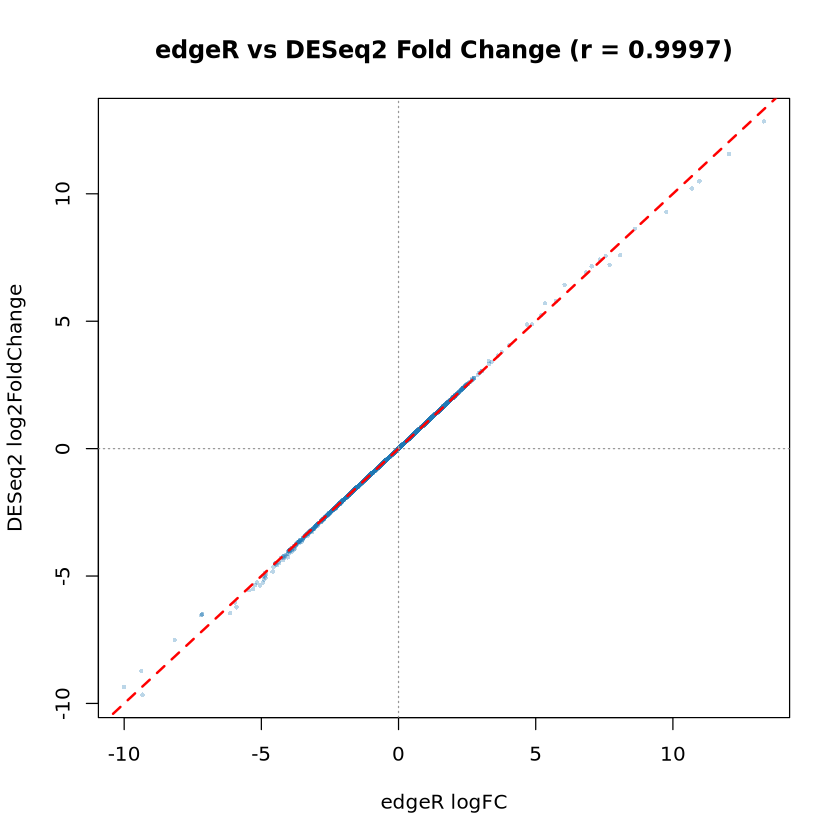

In [5]:
#Loading edgeR results for comparison
edgeR_df <- read.csv("../results/edger_results.csv", check.names = FALSE)
deseq2_df <- read.csv("../results/deseq2_results.csv", check.names = FALSE)

merged_df <- merge(
  edgeR_df,
  deseq2_df,
  by = "gene_id",
  suffixes = c("_edger", "_deseq")
)
stopifnot(nrow(merged_df) == PAPER_FILTERED_GENES)

#Calculating fold changes
pearson_r <- cor(merged_df$logFC, merged_df$log2FoldChange, method="pearson")
spearman_r <- cor(merged_df$logFC, merged_df$log2FoldChange, method="spearman")

print(paste0("Pearson r:  ", round(pearson_r, 5)))
print(paste0("Spearman r: ", round(spearman_r, 5)))

#Plotting comparison for edgeR and DESeq2
draw_edgeR_DESeq2_comparison <- function() {
  par(bg = "white")
plot(
  merged_df$logFC,
  merged_df$log2FoldChange,
  pch = 16,
  cex = 0.5,
  col = rgb(0.12, 0.47, 0.71, alpha = 0.3),
  xlab = "edgeR logFC",
  ylab = "DESeq2 log2FoldChange",
  main = paste0("edgeR vs DESeq2 Fold Change (r = ", round(pearson_r, 4), ")")
)
abline(a = 0, b = 1, col = "red", lwd = 2, lty = 2)
abline(h = 0, v = 0, col = "gray60", lty = 3)
}

draw_edgeR_DESeq2_comparison()

#Scatter plot


png(file.path("../images", "edgeR_DESeq2_comparison.png"),
    width = 7, height = 7, units = "in", res = 300, bg = "white")
draw_edgeR_DESeq2_comparison()   # saves to file
# Add 1:1 identity line (y = x) and zero reference axes
abline(a = 0, b = 1, col = "red", lwd = 2, lty = 2)
abline(h = 0, v = 0, col = "gray60", lty = 3)

dev.off()




In [6]:
#Filtering significant genes for each method
edgeR_genes <- merged_df[merged_df$FDR < 0.05,]
deseq2_genes <- merged_df[merged_df$padj < 0.05,]
stopifnot(nrow(edgeR_genes) == EDGER_SIG_GENES)
stopifnot(nrow(deseq2_genes) == DESEQ2_SIG_GENES)

#Hunting overlapping genes

overlapping_genes <- intersect(edgeR_genes$gene_id, deseq2_genes$gene_id)
pct_overlap <- (length(overlapping_genes) / nrow(deseq2_genes)) * 100
print(paste0("Overlapping genes percentage: ", round(pct_overlap, 2)))

#Mutually exclusive genes
edgeR_genes_only <- setdiff(edgeR_genes$gene_id, deseq2_genes$gene_id)
deseq2_genes_only <- setdiff(deseq2_genes$gene_id, edgeR_genes$gene_id)
stopifnot(length(overlapping_genes) + length(edgeR_genes_only) == EDGER_SIG_GENES )
stopifnot(length(overlapping_genes) + length(deseq2_genes_only) == DESEQ2_SIG_GENES )

print(paste0("Significant genes for edgeR only are: ", EDGER_SIG_GENES - length(overlapping_genes)))
print(paste0("Significant genes for deseq2 only are: ", nrow(deseq2_genes) - length(overlapping_genes)))

[1] "Overlapping genes percentage: 99.63"


[1] "Significant genes for edgeR only are: 596"
[1] "Significant genes for deseq2 only are: 17"


In [7]:
#Finding DESeq2 padj values associated with edgeR only significant genes
edgeR_genes_only_df <- data.frame(gene_id = edgeR_genes_only, padj_deseq2_value = merged_df$padj[match(edgeR_genes_only, merged_df$gene_id)])
median_padj_edgeR <- median(edgeR_genes_only_df$padj_deseq2_value, na.rm = TRUE)
range_padj_edgeR <- range(edgeR_genes_only_df$padj_deseq2_value, na.rm = TRUE)
print(median_padj_edgeR)
print(range_padj_edgeR)

#Finding edgeR FDR values associated with deseq2 only significant genes
deseq2_genes_only_df <- data.frame(gene_id = deseq2_genes_only, FDR_edgeR_value = merged_df$FDR[match(deseq2_genes_only, merged_df$gene_id)])
median_FDR_deseq2 <- median(deseq2_genes_only_df$FDR_edgeR_value, na.rm = TRUE)
range_FDR_deseq2 <- range(deseq2_genes_only_df$FDR_edgeR_value, na.rm = TRUE)
print(median_FDR_deseq2)
print(range_FDR_deseq2)

#For all overlapping significant genes, finding logCPM or basemean and fold change
overlapping_vec <- unlist(overlapping_genes)
overlapping_genes_df <- data.frame(gene_id = overlapping_vec,
logCPM = merged_df$logCPM[match(overlapping_vec, merged_df$gene_id)],
basemean = merged_df$baseMean[match(overlapping_vec, merged_df$gene_id)],
log2FoldChange = merged_df$log2FoldChange[match(overlapping_vec, merged_df$gene_id)]
 )


mean_logCPM_overlap <- mean(overlapping_genes_df$logCPM, na.rm = TRUE)
mean_baseMean_overlap <- mean(overlapping_genes_df$basemean, na.rm = TRUE)
mean_log2FoldChange_overlap <- mean(overlapping_genes_df$log2FoldChange, na.rm = TRUE)
print(mean_logCPM_overlap)
print(mean_baseMean_overlap)
print(mean_log2FoldChange_overlap)

[1] 0.07530565
[1] 0.05001619 0.19856064
[1] 0.05230151


[1] 0.05004955 0.05822051
[1] 4.425834
[1] 795.196
[1] -0.1709324


In [8]:
# Compare the three groups of significant genes
groups <- list(
  both        = overlapping_genes,
  edgeR_only  = edgeR_genes_only,
  deseq2_only = deseq2_genes_only
)
parameters <- c("logCPM", "baseMean", "log2FoldChange")

results_table <- data.frame()

for (group_name in names(groups)) {
  sub_df <- merged_df[merged_df$gene_id %in% groups[[group_name]], ]

  for (col in parameters) {
    vals <- sub_df[[col]]
    if (col == "log2FoldChange") {
      vals <- abs(vals)          # size of change, regardless of direction
    }

    new_row <- data.frame(
      Group     = group_name,
      n_genes   = nrow(sub_df),
      Parameter = col,
      Mean      = mean(vals),
      Median    = median(vals)
    )
    results_table <- rbind(results_table, new_row)
  }
}

print(results_table)

# Group sizes must match the overlap counts
stopifnot(results_table$n_genes[results_table$Group == "both"][1]        == 4531)
stopifnot(results_table$n_genes[results_table$Group == "edgeR_only"][1]  == 596)
stopifnot(results_table$n_genes[results_table$Group == "deseq2_only"][1] == 17)

        Group n_genes      Parameter         Mean       Median
1        both    4531         logCPM 4.425834e+00    4.4842162
2        both    4531       baseMean 7.951960e+02  242.7542673
3        both    4531 log2FoldChange 1.155297e+00    0.9090435
4  edgeR_only     596         logCPM 2.110423e+00    1.7191258
5  edgeR_only     596       baseMean 1.024087e+02   34.4416084
6  edgeR_only     596 log2FoldChange 8.413762e-01    0.8076452
7 deseq2_only      17         logCPM 7.811984e+00    6.9447562
8 deseq2_only      17       baseMean 2.245321e+04 1349.2082455
9 deseq2_only      17 log2FoldChange 4.019581e-01    0.3799217


In [9]:
# Diagnostic: DESeq2 with a likelihood ratio test instead of the Wald test
dds_lrt <- DESeq(dds, test = "LRT", reduced = ~ 1)
res_lrt <- results(dds_lrt, independentFiltering = FALSE, cooksCutoff = FALSE)

lrt_sig <- rownames(res_lrt)[res_lrt$padj < 0.05]
print(length(lrt_sig))

using pre-existing size factors

estimating dispersions

found already estimated dispersions, replacing these

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

fitting model and testing



[1] 4545


In [10]:
#Writing another table to do dispersion comparison

dispersion_deseq2_data <- data.frame(gene_id = rownames(dds), dispersions = dispersions(dds))
dispersion_edgeR_data <- read.csv("../results/edgeR_dispersion_results.csv")

stopifnot(nrow(dispersion_deseq2_data) == nrow(dispersion_edgeR_data))
write.csv(
  dispersion_deseq2_data,
  file = file.path(out_dir, "deseq2_dispersion_results.csv"),
  row.names = FALSE
)

merged_dispersion_df <- merge(
  dispersion_deseq2_data,
  dispersion_edgeR_data,
  by = "gene_id",
  suffixes = c("_deseq", "_edger")
)

stopifnot(nrow(merged_dispersion_df) == PAPER_FILTERED_GENES)
stopifnot(!anyNA(merged_dispersion_df$Ratio))

merged_dispersion_df$Ratio <- merged_dispersion_df$dispersions_deseq / merged_dispersion_df$dispersions_edger

In [13]:
head(merged_dispersion_df)

,gene_id,dispersions_deseq,dispersions_edger,Ratio
,<chr>,<dbl>,<dbl>,<dbl>
1,ENSG00000000003,0.02832891,0.02815720,1.006098
2,ENSG00000000419,0.02625316,0.02470938,1.062478
3,ENSG00000000457,0.02196124,0.01774093,1.237885
4,ENSG00000000460,0.03456572,0.02490586,1.387855
5,ENSG00000000971,0.16673827,0.03241336,5.144122
6,ENSG00000001036,0.02130832,0.02112354,1.008747


In [18]:
#Finding median ratio for all genes, overlapping genes, edgeR and DESeq2 genes only

median_ratio_all <- median(merged_dispersion_df$Ratio, na.rm=TRUE)
filtered_overlap_df <- merged_dispersion_df[merged_dispersion_df$gene_id %in% overlapping_genes, ]
filtered_edgeR_df   <- merged_dispersion_df[merged_dispersion_df$gene_id %in% edgeR_genes_only, ]
filtered_deseq2_df  <- merged_dispersion_df[merged_dispersion_df$gene_id %in% deseq2_genes_only, ]

stopifnot(nrow(filtered_overlap_df) == 4531)
stopifnot(nrow(filtered_edgeR_df)   == 596)
stopifnot(nrow(filtered_deseq2_df)  == 17)

print(median_ratio_all)
print(median_ratio_overlapping)
print(median_ratio_edgeR)
print(median_ratio_deseq2)


[1] 1.082669
[1] 1.059246


[1] 1.966987
[1] 0.9251696


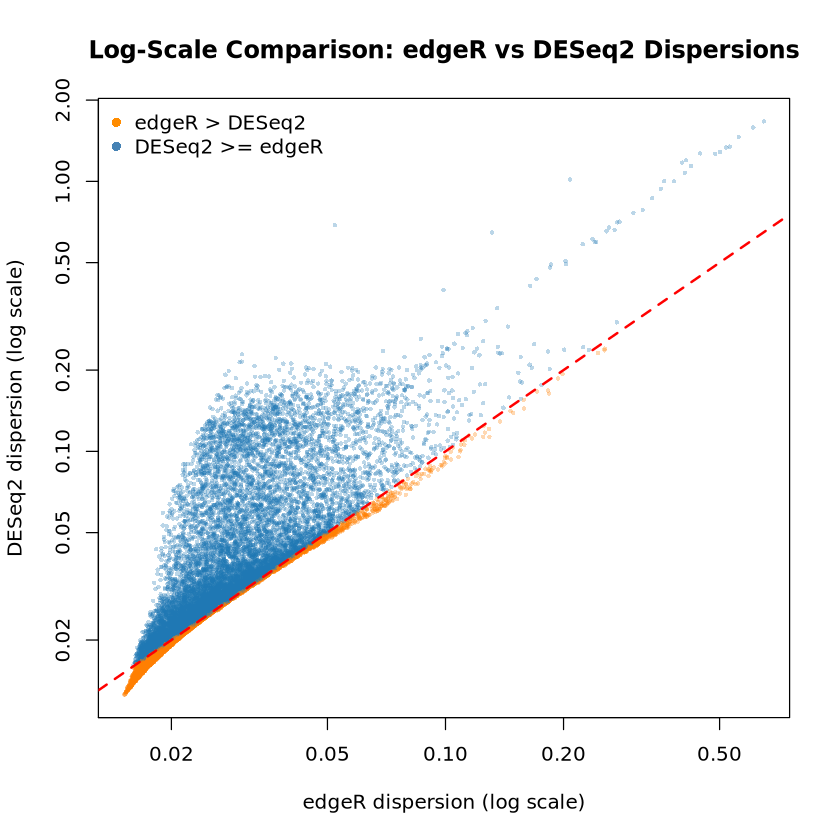

In [25]:
draw_logscale_comparison <- function() {
  par(bg = "white")
  
  # Orange where edgeR > DESeq2, blue where DESeq2 >= edgeR
  pt_colors <- ifelse(
    merged_dispersion_df$dispersions_edger > merged_dispersion_df$dispersions_deseq,
    rgb(1.0, 0.5, 0.0, alpha = 0.3),   # Orange
    rgb(0.12, 0.47, 0.71, alpha = 0.3) # Blue
  )
  
  plot(
    merged_dispersion_df$dispersions_edger,
    merged_dispersion_df$dispersions_deseq,
    log = "xy",
    pch = 16,
    cex = 0.5,
    col = pt_colors,
    xlab = "edgeR dispersion (log scale)",
    ylab = "DESeq2 dispersion (log scale)",
    main = "Log-Scale Comparison: edgeR vs DESeq2 Dispersions"
  )
  
  abline(a = 0, b = 1, col = "red", lwd = 2, lty = 2)
  
  legend(
    "topleft",
    legend = c("edgeR > DESeq2", "DESeq2 >= edgeR"),
    col = c("darkorange", "steelblue"),
    pch = 16,
    bty = "n"
  )
}

draw_logscale_comparison()